In [1]:
import os
import sys
sys.path.append("..")

from src.data_loader import load_data
from src.eda import *
from src.visualization import *

# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 50)

print("Bibliotecas carregadas com sucesso!")


Bibliotecas carregadas com sucesso!


In [2]:
df = load_data("../data/raw/dataset.csv") # Carrega o dataset

In [3]:
df.head() # Primeiras cinco linhas do dataset

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Physical_Activity_Level,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Diet_Quality,Sugar_Intake_Level,Sleep_Hours,Stress_Level,Smoking_Status,Alcohol_Consumption,Family_History_Diabetes,Hypertension,Heart_Disease,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk,BMI_CATEGORY
0,1,32.0,Male,Mexico,182.1,65.8,19.8,71.2,88.4,10.4,149.5,27.4,94,61,138.7,40.1,152.3,250.8,119,Moderate,2.2,106.1,Healthy,Low,7.9,Moderate,Former,Never,Yes,No,Yes,Yes,No,Good,Retired,Rural,4.4,60,Healthy Diet Plan,Yes,Moderate,Normal
1,2,42.0,Other,Saudi Arabia,148.5,101.2,45.9,121.8,247.3,11.3,199.3,18.3,148,100,286.8,35.6,110.4,287.9,59,High,6.3,96.1,Healthy,Low,6.2,Moderate,Current,Frequently,Yes,No,Yes,Yes,Yes,Average,Government,Rural,2.1,99,Begin Diabetes Management Plan,Yes,High,Obese
2,3,89.0,Other,Argentina,158.1,NaN,37.9,131.8,141.9,6.3,219.6,23.9,101,108,129.4,32.1,156.7,329.3,104,High,0.6,68.7,Average,High,4.8,High,Never,Frequently,Yes,No,No,Yes,No,Average,Government,Urban,2.8,80,Strict Blood Sugar Monitoring,Yes,High,Obese
3,4,87.0,Other,United States,190.9,95.9,26.3,99.1,90.1,7.4,217.7,36.7,120,63,168.2,61.9,63.4,308.8,58,High,7.7,23.1,Average,High,4.2,High,Current,Occasionally,Yes,Yes,No,No,No,Average,Business,Rural,1.5,82,Begin Diabetes Management Plan,Yes,High,Overweight
4,5,27.0,Other,Australia,156.9,101.9,41.4,77.1,93.8,12.0,153.5,22.3,190,90,281.5,37.4,66.5,206.6,104,Moderate,4.7,131.2,Poor,High,9.9,Low,Never,Occasionally,No,Yes,Yes,Yes,Yes,Poor,Private,Rural,1.6,93,Begin Diabetes Management Plan,Yes,High,Obese


In [4]:
df.tail() # últimas cinco linhas do dataset

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Physical_Activity_Level,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Diet_Quality,Sugar_Intake_Level,Sleep_Hours,Stress_Level,Smoking_Status,Alcohol_Consumption,Family_History_Diabetes,Hypertension,Heart_Disease,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk,BMI_CATEGORY
49995,49996,52.0,Female,United Kingdom,153.9,107.4,45.3,75.9,248.8,9.9,191.5,15.4,97,94,193.1,64.7,164.2,159.0,113,Low,NaN,39.5,Poor,Low,9.4,Low,Former,Occasionally,Yes,No,No,No,Yes,Average,Retired,Urban,3.5,86,Consult Endocrinologist Immediately,Yes,High,Obese
49996,49997,53.0,Male,United Kingdom,179.6,64.0,19.8,114.5,198.4,6.3,110.0,13.3,121,120,127.2,86.1,188.9,169.3,83,High,5.1,80.9,Poor,High,6.9,Low,Current,Occasionally,No,No,Yes,Yes,No,Average,Government,Urban,3.4,49,Weight Management Program,No,Moderate,Normal
49997,49998,88.0,Male,Brazil,194.1,65.6,17.4,96.1,118.8,NaN,208.4,30.5,176,119,137.6,54.7,90.1,193.6,93,Moderate,9.4,106.8,Poor,High,4.4,Moderate,Never,Frequently,Yes,Yes,No,Yes,Yes,Poor,Retired,Urban,2.6,100,Begin Diabetes Management Plan,Yes,High,Underweight
49998,49999,23.0,Other,Bangladesh,168.0,73.9,26.2,131.4,139.5,9.2,84.7,14.8,141,82,306.8,72.2,191.4,204.9,95,Low,2.5,62.2,Healthy,Moderate,6.1,High,Never,Never,No,No,No,Yes,Yes,Good,Private,Urban,2.7,52,Increase Physical Activity,No,Moderate,Overweight
49999,50000,24.0,Female,Australia,152.8,94.6,40.5,66.1,123.5,6.8,195.3,31.7,166,107,316.0,47.5,110.8,254.4,113,Low,2.4,1.6,Average,Moderate,4.5,Moderate,Former,Frequently,No,Yes,No,Yes,Yes,Good,Retired,Urban,3.9,91,Consult Endocrinologist Immediately,Yes,High,Obese


In [5]:
df.shape # Quantidade de linhas e colunas do dataset

(50000, 42)

In [6]:
df.info() # Tipos de dados das colunas do dataset

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 42 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Patient_ID                  50000 non-null  int64  
 1   Age                         49503 non-null  float64
 2   Gender                      50000 non-null  str    
 3   Country                     50000 non-null  str    
 4   Height_cm                   47055 non-null  float64
 5   Weight_kg                   47038 non-null  float64
 6   BMI                         50000 non-null  float64
 7   Waist_Circumference_cm      50000 non-null  float64
 8   Blood_Glucose               49041 non-null  float64
 9   HbA1c                       48026 non-null  float64
 10  Fasting_Blood_Sugar         50000 non-null  float64
 11  Insulin_Level               50000 non-null  float64
 12  Blood_Pressure_Systolic     50000 non-null  int64  
 13  Blood_Pressure_Diastolic    50000 non-null

Estatísticas Descritivas das Variáveis Numéricas presente no dataset

In [7]:
tabela_estatistica = df.describe()

tabela_estatistica = tabela_estatistica.drop(columns=["Patient_ID"])

tabela_estatistica = tabela_estatistica.rename(index={
    "count": "Quantidade",
    "mean": "Média",
    "std": "Desvio padrão",
    "min": "Mínimo",
    "25%": "Q1",
    "50%": "Mediana",
    "75%": "Q3",
    "max": "Máximo"
})

tabela_estatistica.round(2)

,Age,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Sleep_Hours,Daily_Water_Intake_L,Diabetes_Risk_Score
Quantidade,49503.00,47055.00,47038.00,50000.00,50000.00,49041.00,48026.00,50000.00,50000.00,50000.00,50000.00,49000.00,49000.00,49000.00,49000.00,50000.00,48008.00,48036.00,47983.00,50000.00,50000.00
Média,53.87,170.02,87.46,30.92,99.96,159.91,8.49,142.61,23.48,140.17,90.04,220.17,57.37,135.01,229.54,85.12,5.02,89.93,6.50,3.00,74.04
Desvio padrão,21.13,14.46,24.50,10.29,23.09,52.04,2.31,44.68,12.40,29.17,17.58,57.79,18.72,49.14,98.23,20.39,2.88,52.03,2.03,1.15,15.60
Mínimo,18.00,145.00,45.00,11.90,60.00,70.00,4.50,65.00,2.00,90.00,60.00,120.00,25.00,50.00,60.00,50.00,0.00,0.00,3.00,1.00,13.00
Q1,35.00,157.60,66.30,22.70,80.00,114.70,6.50,103.90,12.80,115.00,75.00,169.80,41.30,92.50,144.70,68.00,2.50,44.90,4.70,2.00,64.00
Mediana,54.00,170.00,87.30,30.00,99.80,159.90,8.50,142.60,23.40,140.00,90.00,220.40,57.30,135.10,229.50,85.00,5.00,89.80,6.50,3.00,75.00
Q3,72.00,182.60,108.60,37.80,119.90,205.10,10.50,181.50,34.30,165.00,105.00,270.50,73.60,177.70,314.60,103.00,7.50,135.20,8.30,4.00,86.00
Máximo,90.00,195.00,130.00,61.70,140.00,250.00,12.50,220.00,45.00,190.00,120.00,320.00,90.00,220.00,400.00,120.00,10.00,180.00,10.00,5.00,100.00


In [8]:
get_missing_values(df) # Quantidade e percentual de valores ausentes por coluna com valores ausentes

,qtd_ausentes,pct_ausentes
Weight_kg,2962,5.92
Height_cm,2945,5.89
Sleep_Hours,2017,4.03
Exercise_Hours_Per_Week,1992,3.98
HbA1c,1974,3.95
Daily_Walking_Minutes,1964,3.93
LDL,1000,2.00
Triglycerides,1000,2.00
Total_Cholesterol,1000,2.00
HDL,1000,2.00


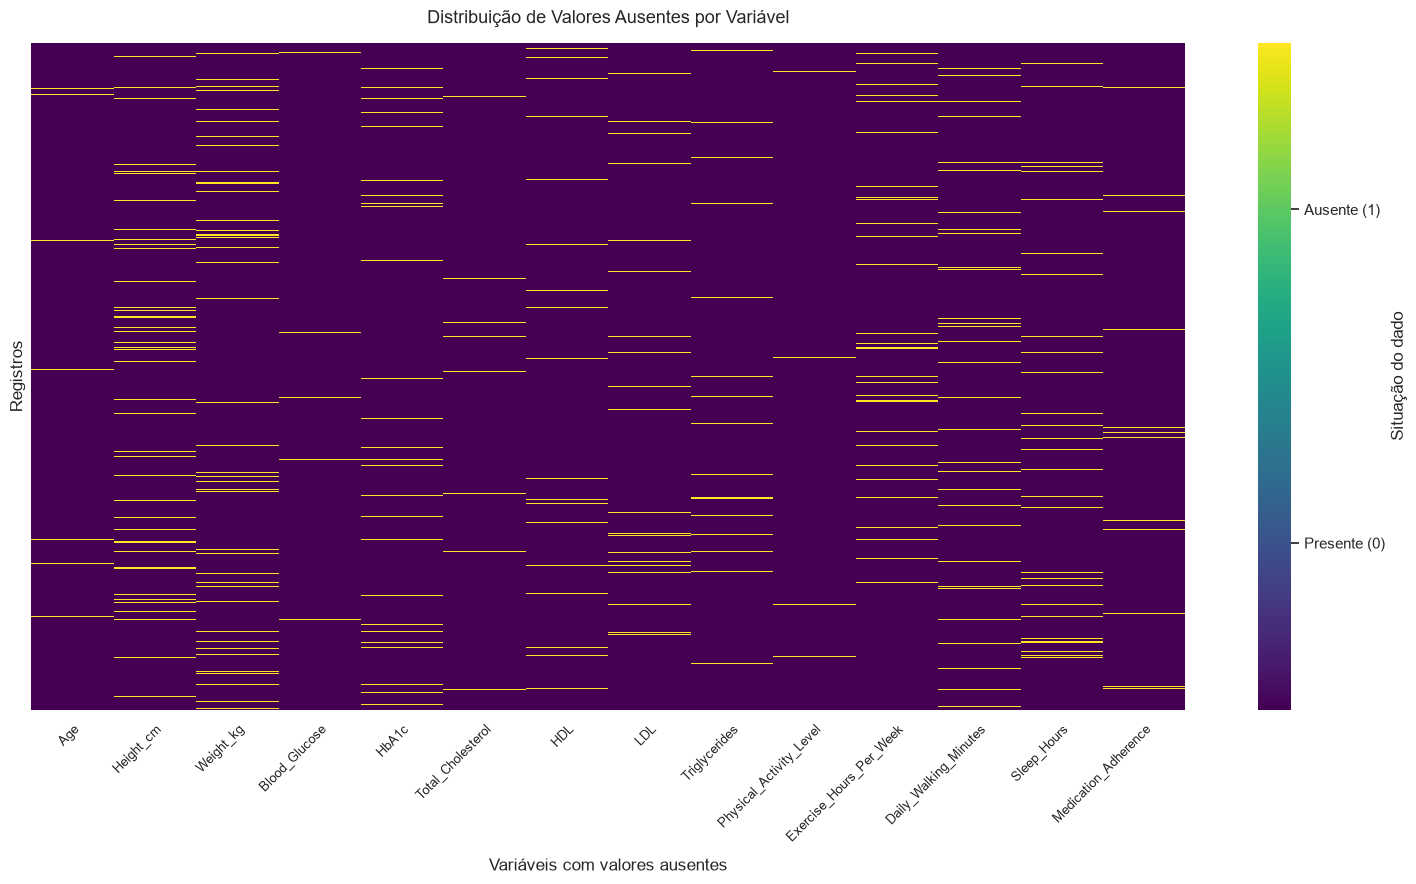

In [9]:
plot_missing_values_heatmap(df) # Gráfico de calor das variáveis com valores ausentes

In [10]:
duplicados = df.duplicated().sum()
print(f"Número de linhas totalmente duplicadas: {duplicados}")

duplicados_sem_id = df.drop(columns=["Patient_ID"]).duplicated().sum()
print(f"Número de linhas duplicadas (ignorando o Id): {duplicados_sem_id}")

Número de linhas totalmente duplicadas: 0
Número de linhas duplicadas (ignorando o Id): 0


In [11]:
df.nunique() # cardinalidade por coluna

Patient_ID                    50000
Age                              73
Gender                            3
Country                          25
Height_cm                       501
Weight_kg                       851
BMI                             497
Waist_Circumference_cm          801
Blood_Glucose                  1801
HbA1c                            81
Fasting_Blood_Sugar            1551
Insulin_Level                   431
Blood_Pressure_Systolic         101
Blood_Pressure_Diastolic         61
Total_Cholesterol              2001
HDL                             651
LDL                            1701
Triglycerides                  3401
Heart_Rate                       71
Physical_Activity_Level           3
Exercise_Hours_Per_Week         101
Daily_Walking_Minutes          1801
Diet_Quality                      3
Sugar_Intake_Level                3
Sleep_Hours                      71
Stress_Level                      3
Smoking_Status                    3
Alcohol_Consumption         

In [12]:
resultado_invalidos = verificar_valores_invalidos(df)

resultado_invalidos

,Variavel,Limite_Minimo,Limite_Maximo,Quantidade_Invalidos,Percentual_Invalidos
0,Age,18,90,0,0.0
1,Height_cm,100,250,0,0.0
2,Weight_kg,20,300,0,0.0
3,BMI,5,100,0,0.0
4,Waist_Circumference_cm,30,250,0,0.0
5,Blood_Glucose,0,1000,0,0.0
6,HbA1c,0,30,0,0.0
7,Fasting_Blood_Sugar,0,1000,0,0.0
8,Insulin_Level,0,10000,0,0.0
9,Blood_Pressure_Systolic,0,400,0,0.0


In [13]:
variaveis_numericas_esperadas = [
    "Age",
    "Height_cm",
    "Weight_kg",
    "BMI",
    "Waist_Circumference_cm",
    "Blood_Glucose",
    "HbA1c",
    "Fasting_Blood_Sugar",
    "Insulin_Level",
    "Blood_Pressure_Systolic",
    "Blood_Pressure_Diastolic",
    "Total_Cholesterol",
    "HDL",
    "LDL",
    "Triglycerides",
    "Heart_Rate",
    "Exercise_Hours_Per_Week",
    "Daily_Walking_Minutes",
    "Sleep_Hours",
    "Daily_Water_Intake_L",
    "Diabetes_Risk_Score"
]

for coluna in variaveis_numericas_esperadas:
    print(f"{coluna}: {df[coluna].dtype}")

Age: float64
Height_cm: float64
Weight_kg: float64
BMI: float64
Waist_Circumference_cm: float64
Blood_Glucose: float64
HbA1c: float64
Fasting_Blood_Sugar: float64
Insulin_Level: float64
Blood_Pressure_Systolic: int64
Blood_Pressure_Diastolic: int64
Total_Cholesterol: float64
HDL: float64
LDL: float64
Triglycerides: float64
Heart_Rate: int64
Exercise_Hours_Per_Week: float64
Daily_Walking_Minutes: float64
Sleep_Hours: float64
Daily_Water_Intake_L: float64
Diabetes_Risk_Score: int64


In [14]:
variaveis_categoricas = [
    "Gender",
    "Country",
    "Physical_Activity_Level",
    "Diet_Quality",
    "Sugar_Intake_Level",
    "Stress_Level",
    "Smoking_Status",
    "Alcohol_Consumption",
    "Family_History_Diabetes",
    "Hypertension",
    "Heart_Disease",
    "Fatty_Liver",
    "PCOS",
    "Medication_Adherence",
    "Work_Type",
    "Residence_Type",
    "AI_Health_Recommendation",
    "Doctor_Consultation_Needed",
    "Diabetes_Risk",
    "BMI_CATEGORY"
]

for coluna in variaveis_categoricas:
    print(f"\n{'=' * 50}")
    print(f"Variável: {coluna}")
    print("-" * 50)

    frequencia = df[coluna].value_counts(dropna=False)
    percentual = df[coluna].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    resultado = pd.DataFrame({
        "Frequência": frequencia,
        "Percentual (%)": percentual.round(2)
    })

    print(resultado)


Variável: Gender
--------------------------------------------------
        Frequência  Percentual (%)
Gender                            
Male         16718           33.44
Other        16677           33.35
Female       16605           33.21

Variável: Country
--------------------------------------------------
                Frequência  Percentual (%)
Country                                   
Malaysia              2083            4.17
Russia                2071            4.14
France                2068            4.14
China                 2065            4.13
Canada                2050            4.10
United Kingdom        2037            4.07
Nigeria               2023            4.05
Indonesia             2011            4.02
Egypt                 2010            4.02
Spain                 2007            4.01
Mexico                1999            4.00
Germany               1999            4.00
South Korea           1997            3.99
South Africa          1996            3.9

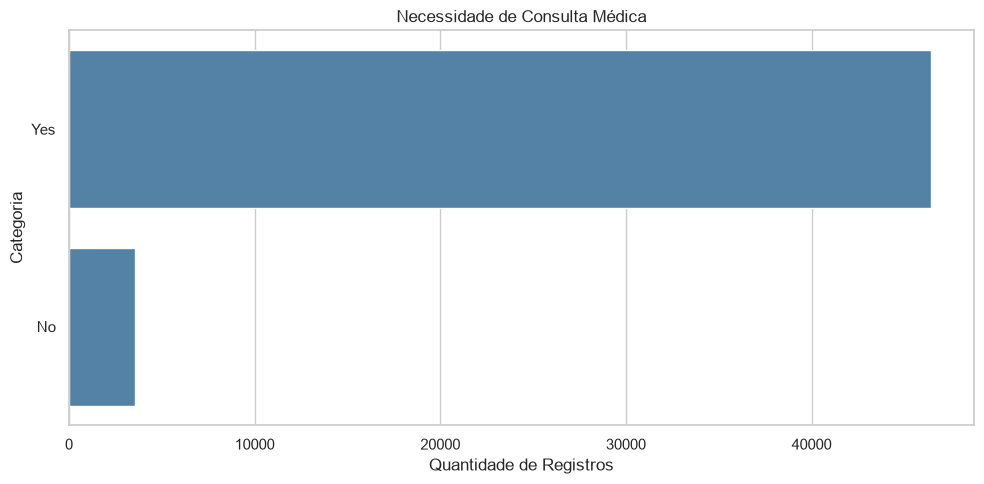

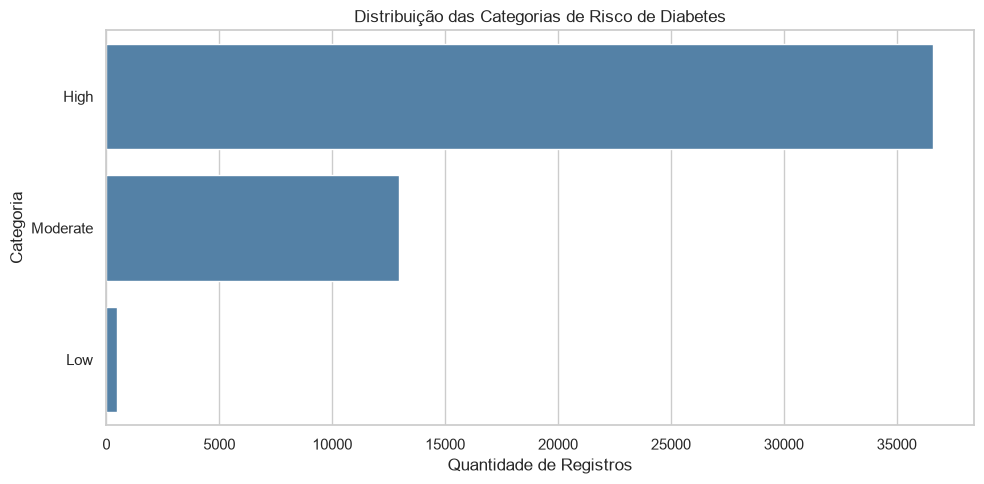

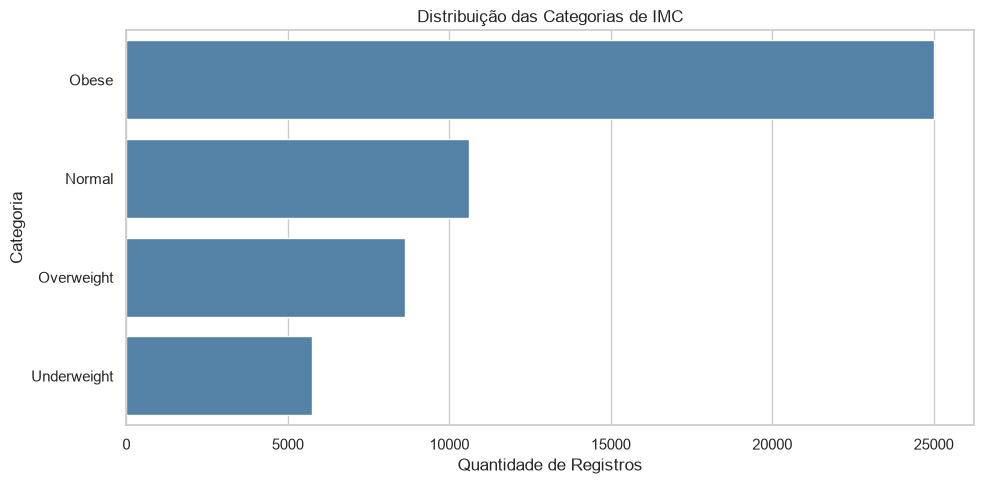

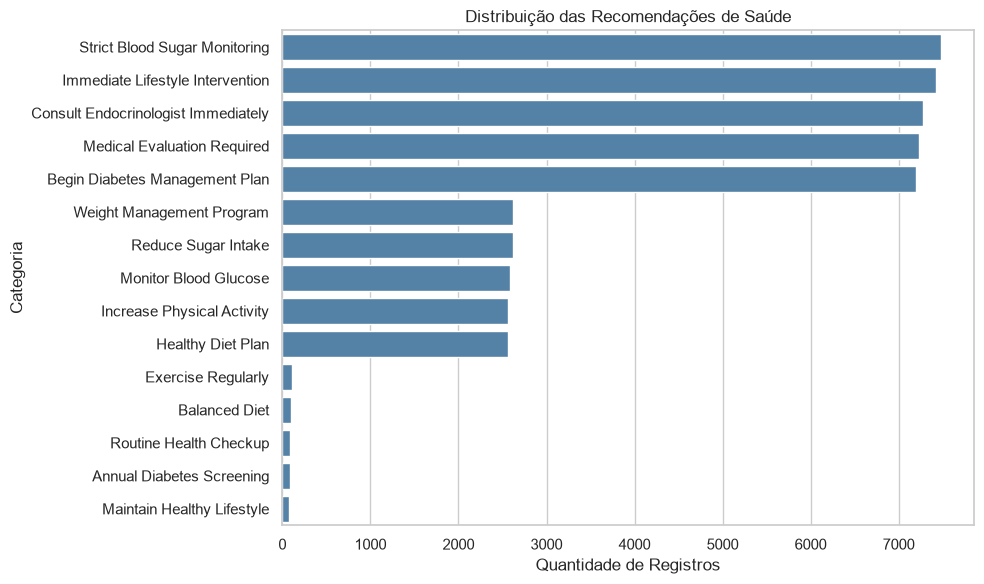

In [15]:

plot_categorical_distribution(
    df,
    "Doctor_Consultation_Needed",
    "Necessidade de Consulta Médica",
    "dist_doctor_consultation.png"
)

plot_categorical_distribution(
    df,
    "Diabetes_Risk",
    "Distribuição das Categorias de Risco de Diabetes",
    "dist_diabetes_risk.png"
)

plot_categorical_distribution(
    df,
    "BMI_CATEGORY",
    "Distribuição das Categorias de IMC",
    "dist_bmi_category.png"
)

plot_categorical_distribution(
    df,
    "AI_Health_Recommendation",
    "Distribuição das Recomendações de Saúde",
    "dist_health_recommendation.png"
)


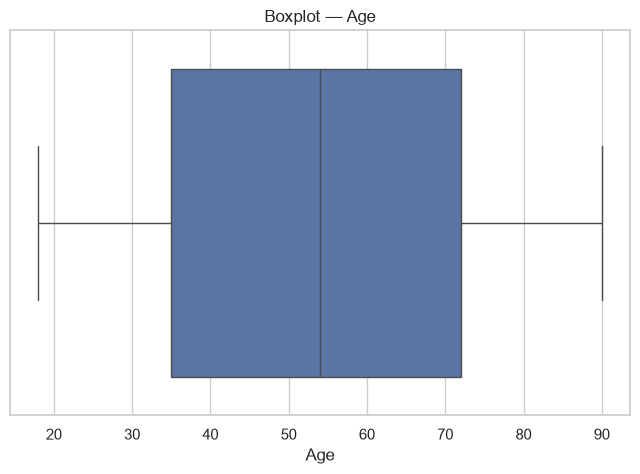

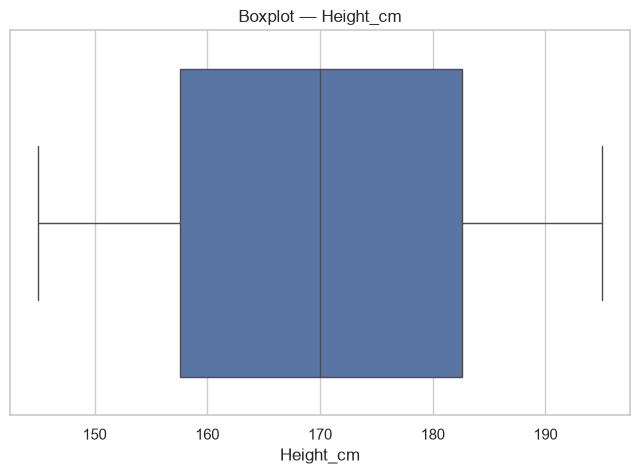

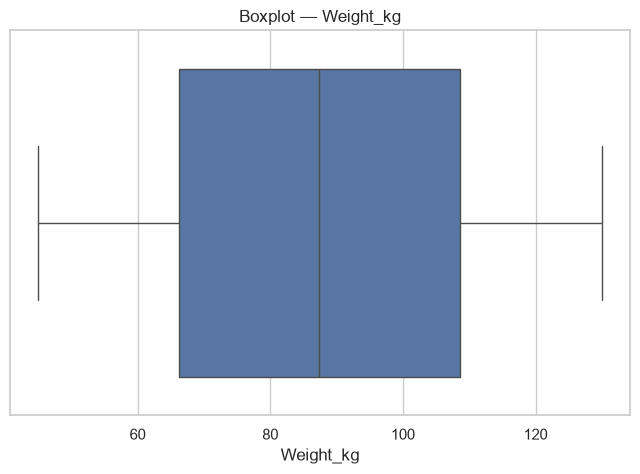

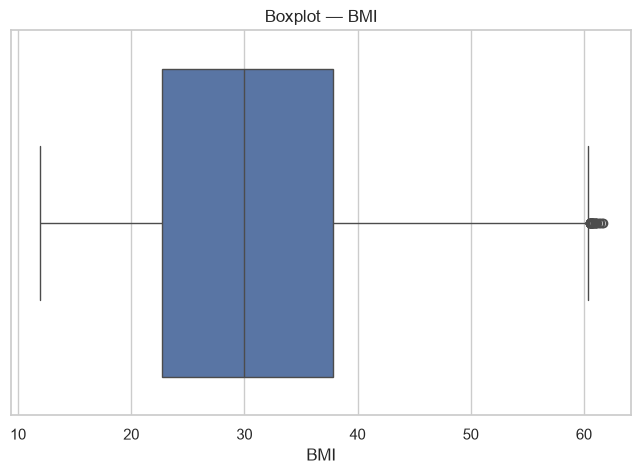

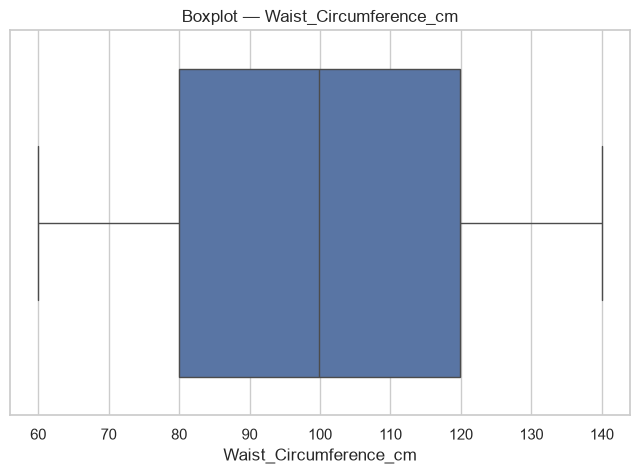

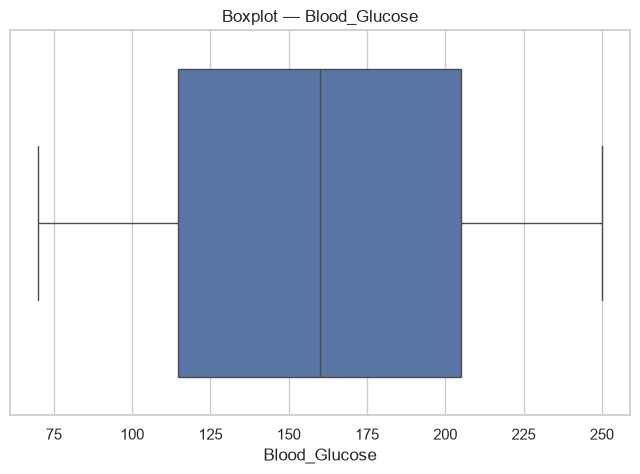

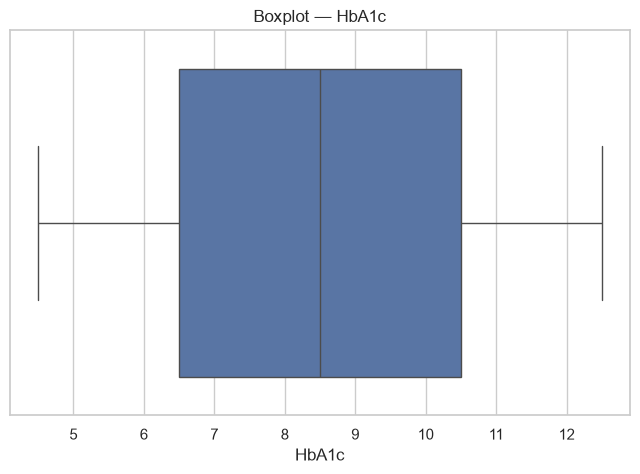

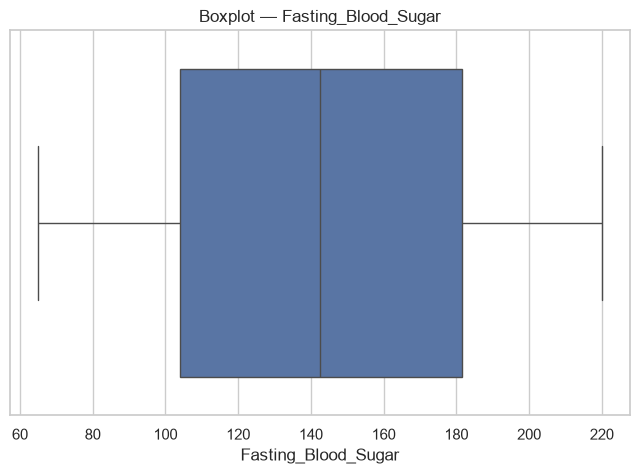

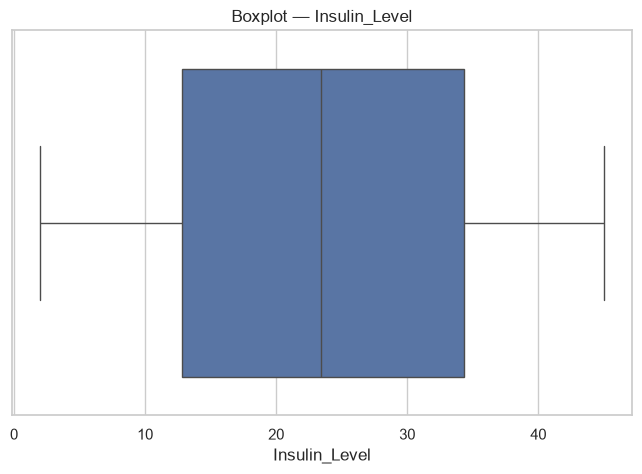

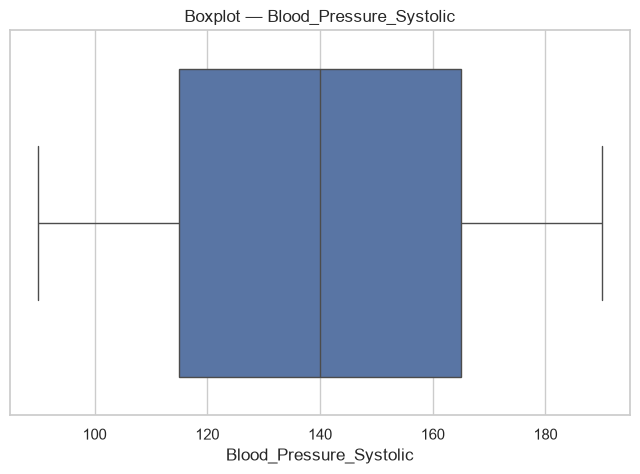

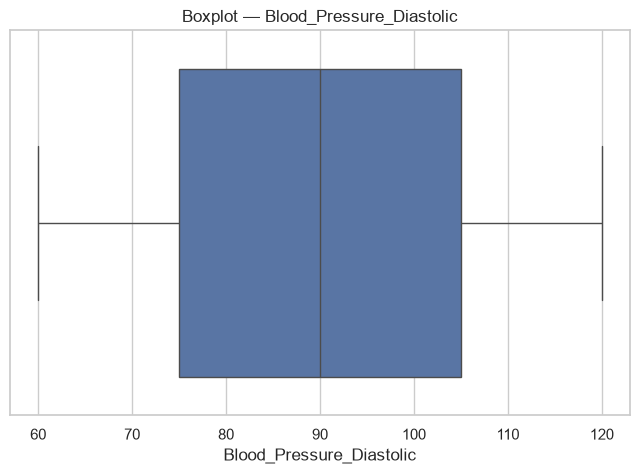

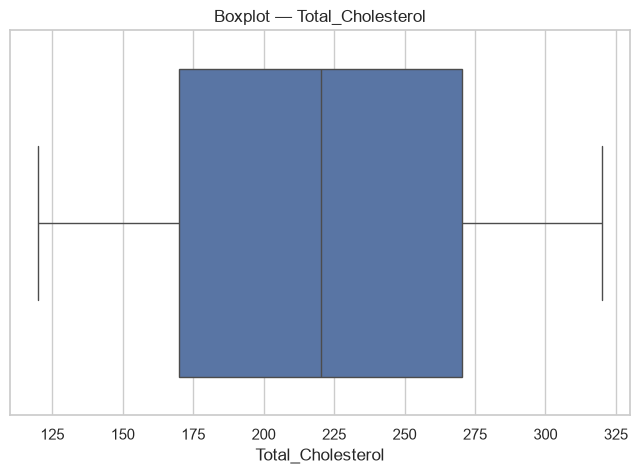

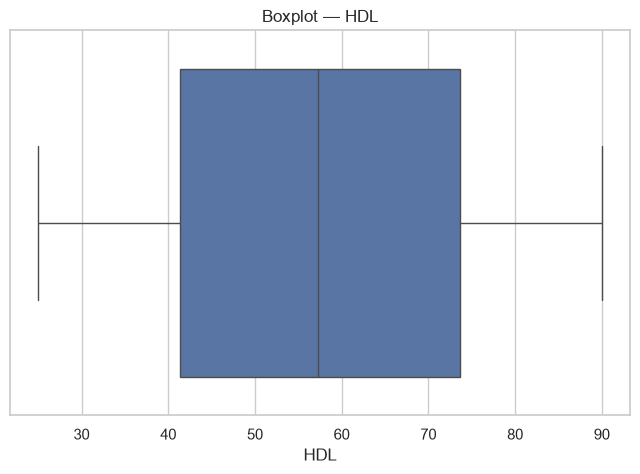

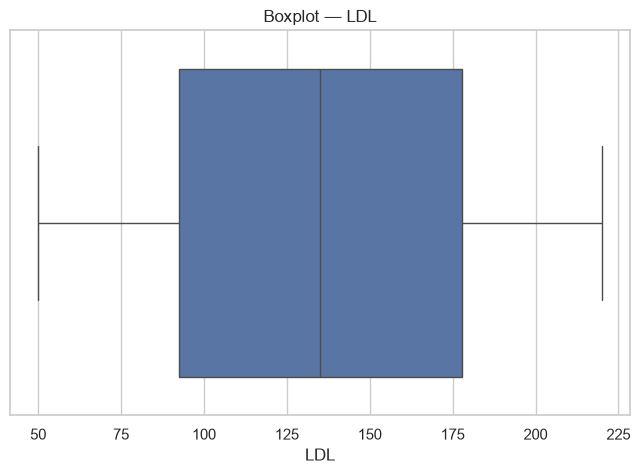

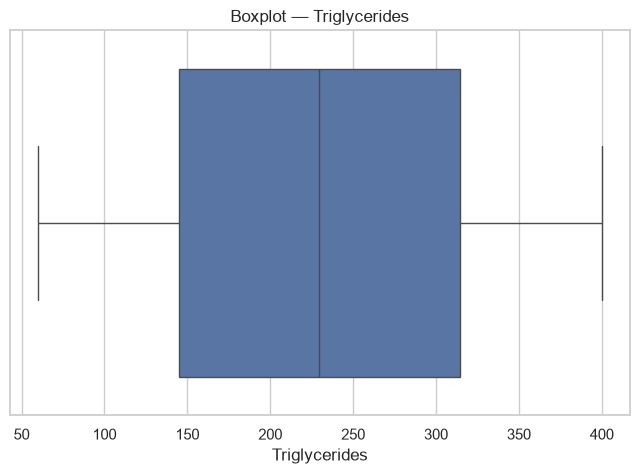

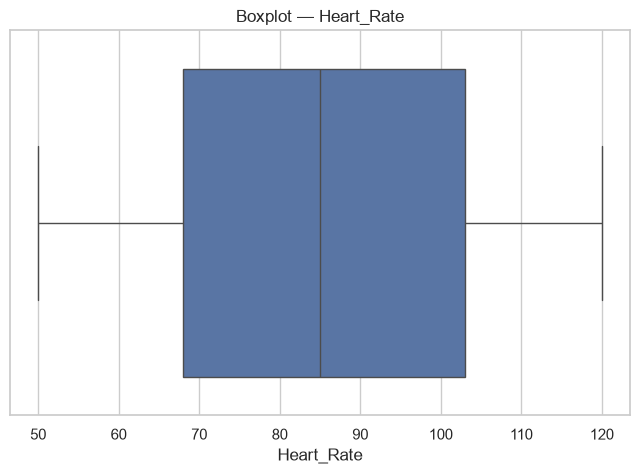

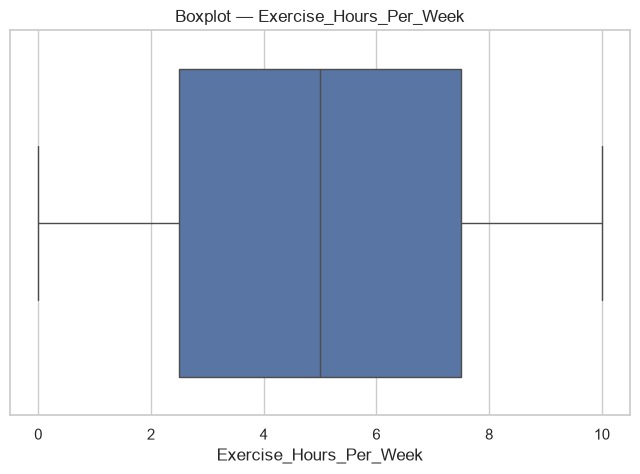

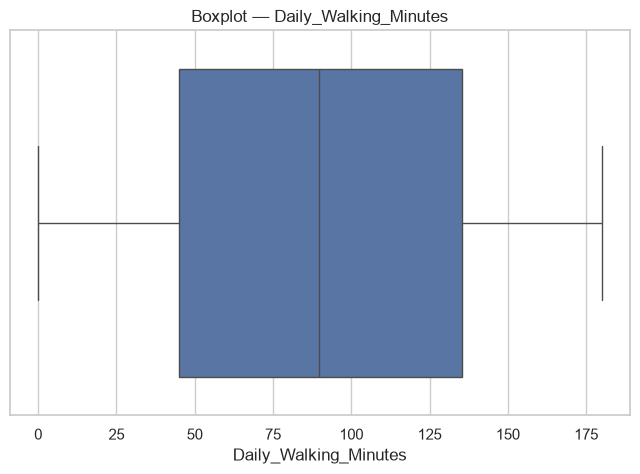

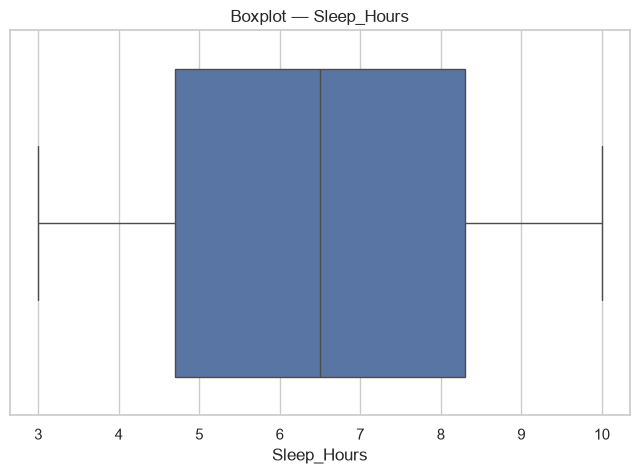

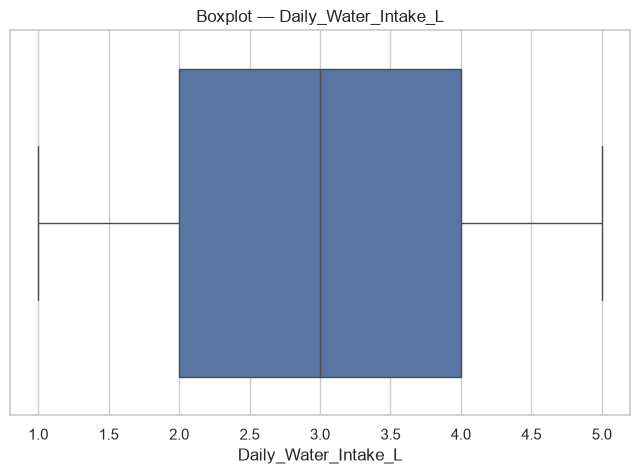

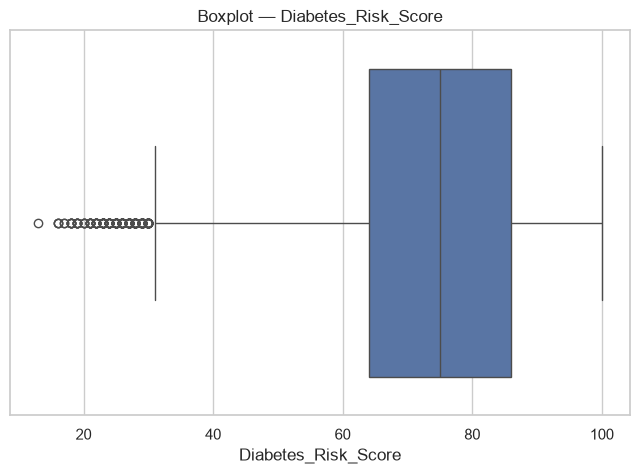

In [16]:
plot_numerical_boxplots(df) # Gráficos de caixa das variáveis numéricas para identificar possíveis outliers

In [17]:
resultado = detectar_outliers_iqr(df, "BMI")

print(f"Q1 = {resultado['Q1']}")
print(f"Q3 = {resultado['Q3']}")
print(f"IQR = {resultado['IQR']}")
print(f"Limite inferior: {resultado['limite_inferior']:.2f}")
print(f"Limite superior: {resultado['limite_superior']:.2f}")
print(f"Quantidade de outliers: {resultado['quantidade_outliers']}")

Q1 = 22.7
Q3 = 37.8
IQR = 15.099999999999998
Limite inferior: 0.05
Limite superior: 60.45
Quantidade de outliers: 28


In [18]:
resultado = detectar_outliers_zscore(df,"BMI")

print(
    f"Quantidade de outliers: "
    f"{resultado['quantidade_outliers']}"
)

resultado["outliers"].head()

Quantidade de outliers: 0


,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Physical_Activity_Level,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Diet_Quality,Sugar_Intake_Level,Sleep_Hours,Stress_Level,Smoking_Status,Alcohol_Consumption,Family_History_Diabetes,Hypertension,Heart_Disease,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk,BMI_CATEGORY,zscore


In [19]:
resultado = detectar_outliers_iqr(df, "Diabetes_Risk_Score")

print(f"Q1 = {resultado['Q1']}")
print(f"Q3 = {resultado['Q3']}")
print(f"IQR = {resultado['IQR']}")
print(f"Limite inferior: {resultado['limite_inferior']:.2f}")
print(f"Limite superior: {resultado['limite_superior']:.2f}")
print(f"Quantidade de outliers: {resultado['quantidade_outliers']}")

Q1 = 64.0
Q3 = 86.0
IQR = 22.0
Limite inferior: 31.00
Limite superior: 119.00
Quantidade de outliers: 237


In [20]:
resultado = detectar_outliers_zscore(df,"Diabetes_Risk_Score")

print(
    f"Quantidade de outliers: "
    f"{resultado['quantidade_outliers']}"
)

resultado["outliers"].head()

Quantidade de outliers: 140


,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Physical_Activity_Level,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Diet_Quality,Sugar_Intake_Level,Sleep_Hours,Stress_Level,Smoking_Status,Alcohol_Consumption,Family_History_Diabetes,Hypertension,Heart_Disease,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk,BMI_CATEGORY,zscore
111,112,20.0,Male,Australia,193.6,69.0,18.4,70.0,148.9,4.6,79.0,2.6,117,81,204.0,76.1,134.7,186.3,54,Moderate,0.8,135.1,Healthy,Low,4.9,Moderate,Never,Frequently,No,Yes,Yes,No,No,Good,Business,Urban,4.9,21,Annual Diabetes Screening,No,Low,Underweight,3.40065
977,978,30.0,Other,United Kingdom,160.8,63.7,24.6,113.3,79.0,4.6,68.1,5.3,91,89,281.1,61.8,72.9,323.7,85,Low,7.9,44.7,Healthy,Low,6.0,Moderate,Current,Never,No,No,Yes,No,No,Good,Private,Urban,3.3,24,Balanced Diet,No,Low,Normal,3.20832
1003,1004,44.0,Other,Mexico,181.4,55.5,16.9,101.8,83.2,5.3,76.1,18.9,171,69,138.9,67.9,63.4,147.0,113,High,5.1,39.1,Average,High,9.8,Low,Former,Never,No,Yes,No,Yes,No,Poor,Student,Urban,3.6,23,Annual Diabetes Screening,No,Low,Underweight,3.27243
1550,1551,47.0,Male,Nigeria,NaN,NaN,15.4,132.1,215.8,6.1,73.7,31.0,110,81,144.9,79.9,217.1,156.0,52,Moderate,5.3,133.4,Average,Low,4.2,Low,Never,Occasionally,No,No,No,Yes,No,Average,Private,Rural,1.2,22,Exercise Regularly,Yes,Low,Underweight,3.33654
1731,1732,41.0,Male,United Kingdom,163.0,60.7,22.8,130.0,185.0,4.6,67.5,7.8,100,110,161.9,36.8,206.5,350.1,91,High,9.4,72.5,Poor,Low,3.7,High,Former,Never,No,No,No,Yes,No,Good,Private,Rural,3.5,25,Balanced Diet,No,Low,Normal,3.14421


In [21]:
variaveis = [
    "Age",
    "Height_cm",
    "Weight_kg",
    "BMI",
    "Waist_Circumference_cm",
    "Blood_Glucose",
    "HbA1c",
    "Fasting_Blood_Sugar",
    "Insulin_Level",
    "Blood_Pressure_Systolic",
    "Blood_Pressure_Diastolic",
    "Total_Cholesterol",
    "HDL",
    "LDL",
    "Triglycerides",
    "Heart_Rate",
    "Exercise_Hours_Per_Week",
    "Daily_Walking_Minutes",
    "Sleep_Hours",
    "Daily_Water_Intake_L",
    "Diabetes_Risk_Score"
]

In [22]:
tabela_assimetria = pd.DataFrame({
    "assimetria": df[variaveis].skew(),
    "curtose": df[variaveis].kurtosis()
}).round(2)

tabela_assimetria

,assimetria,curtose
Age,0.01,-1.21
Height_cm,0.00,-1.21
Weight_kg,0.00,-1.19
BMI,0.43,-0.45
Waist_Circumference_cm,0.01,-1.19
Blood_Glucose,0.01,-1.21
HbA1c,0.00,-1.20
Fasting_Blood_Sugar,-0.00,-1.20
Insulin_Level,0.01,-1.20
Blood_Pressure_Systolic,-0.00,-1.20


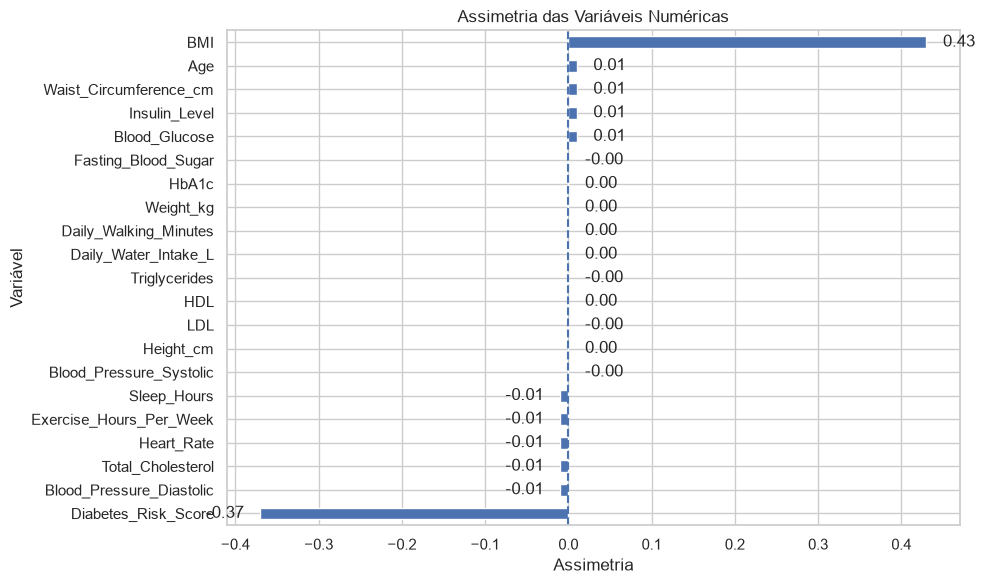

In [23]:
plt.figure(figsize=(10, 6))

dados = tabela_assimetria["assimetria"].sort_values()

ax = dados.plot(kind="barh")

plt.axvline(0, linestyle="--")

for i, valor in enumerate(dados):
    ax.text(
        valor + (0.02 if valor >= 0 else -0.02),
        i,
        f"{valor:.2f}",
        va="center",
        ha="left" if valor >= 0 else "right"
    )

plt.title("Assimetria das Variáveis Numéricas")
plt.xlabel("Assimetria")
plt.ylabel("Variável")

plt.tight_layout()
plt.show()

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

variaveis = [
    coluna for coluna in variaveis_numericas_esperadas
    if coluna in df.columns
]

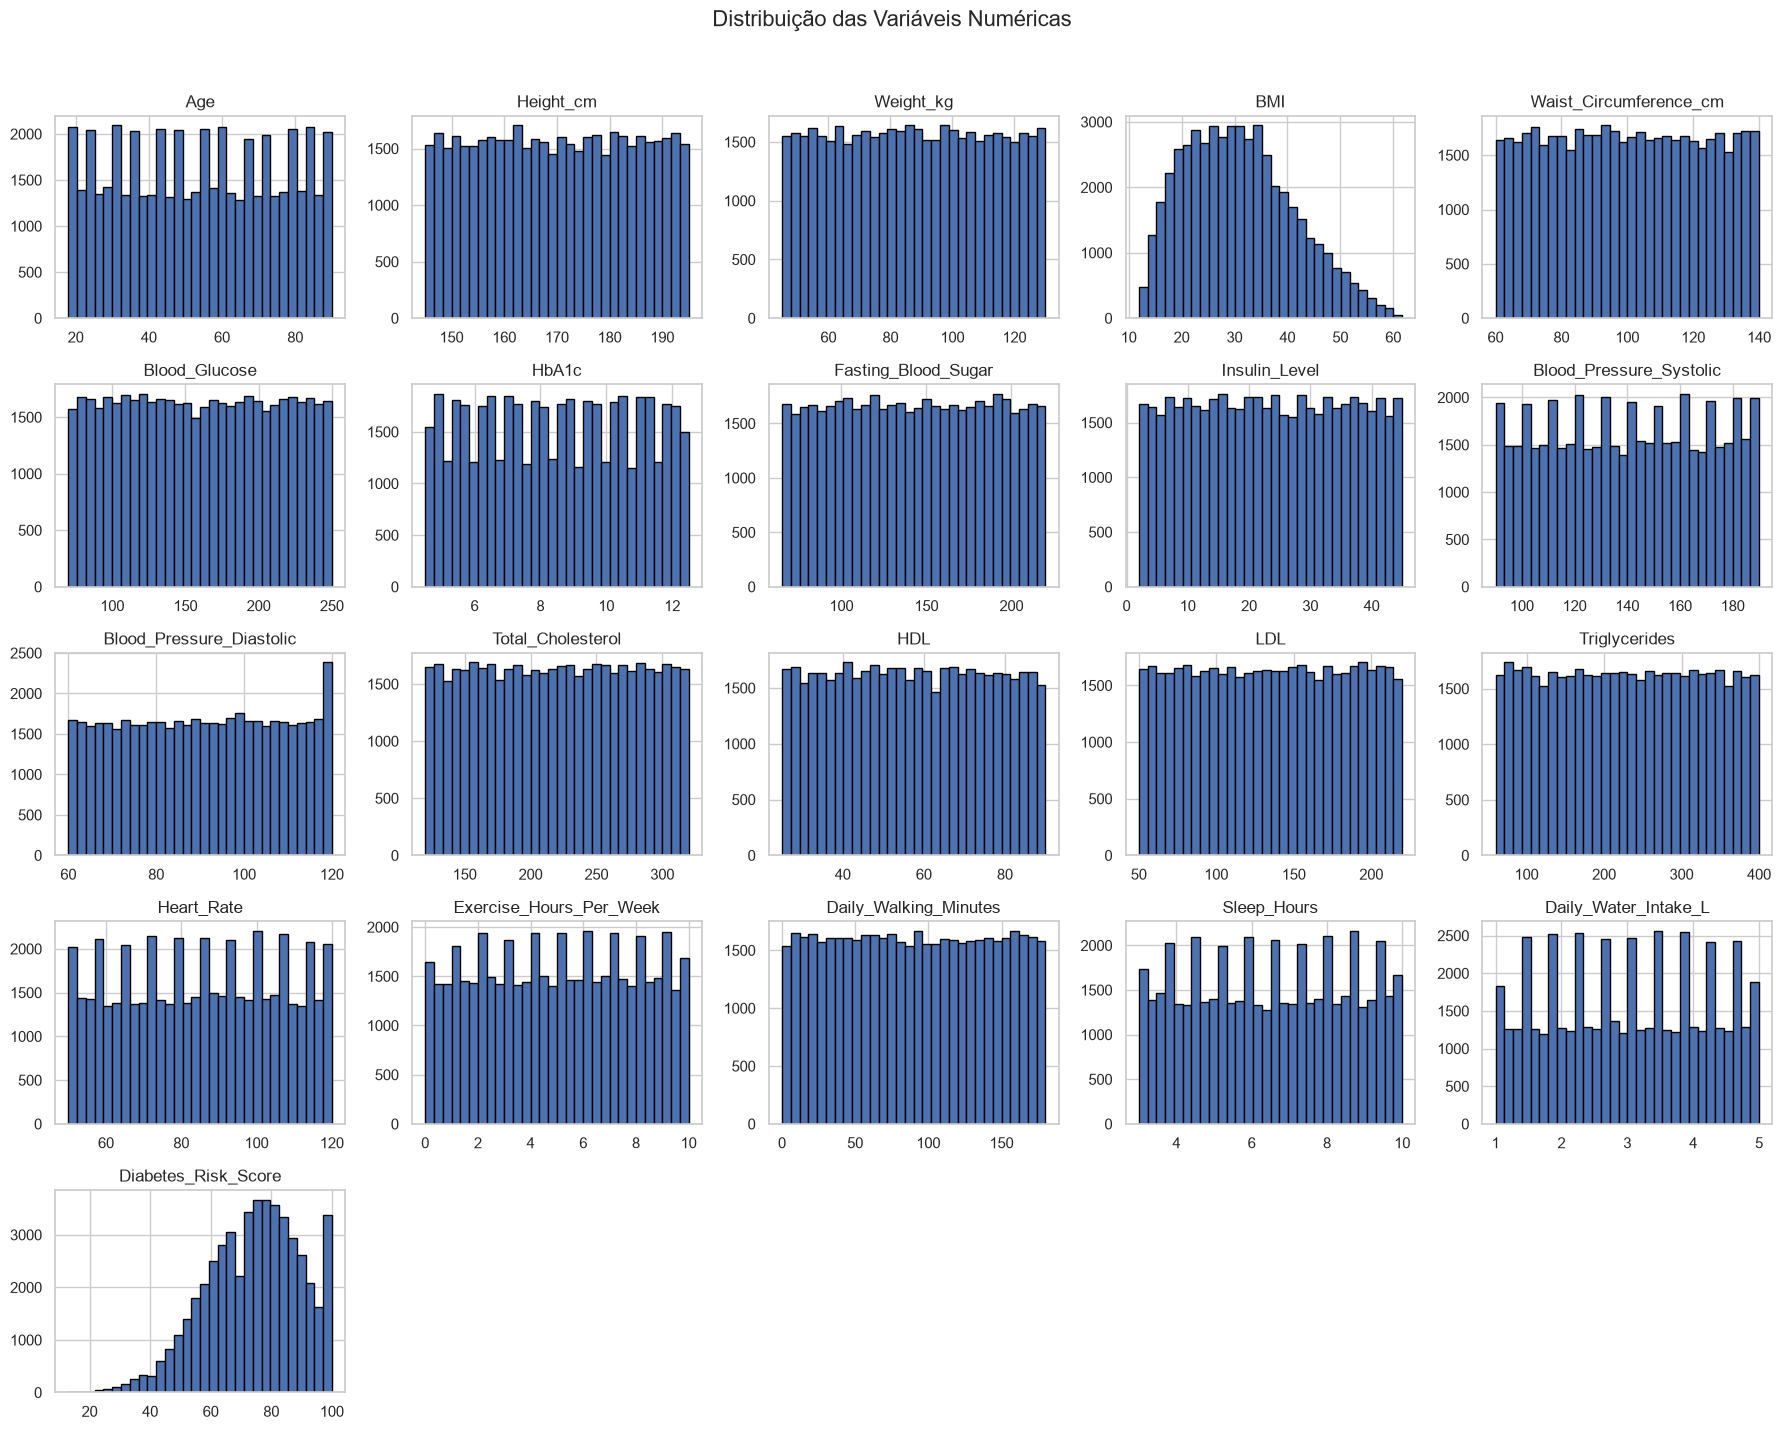

In [25]:
df[variaveis].hist(
    bins=30,
    figsize=(18, 14),
    edgecolor="black"
)

plt.suptitle(
    "Distribuição das Variáveis Numéricas",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

In [26]:
matriz_corr = get_correlation_matrix(df, variaveis)

matriz_corr.round(2)

,Age,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Sleep_Hours,Daily_Water_Intake_L,Diabetes_Risk_Score
Age,1.00,-0.01,-0.00,-0.00,-0.00,0.00,0.01,0.01,0.00,0.00,0.00,-0.01,0.00,0.00,-0.00,-0.00,-0.01,-0.00,0.00,0.00,0.28
Height_cm,-0.01,1.00,-0.00,-0.52,0.01,0.00,-0.00,0.00,0.00,0.01,0.00,0.01,0.00,0.00,0.00,-0.01,-0.00,0.00,0.00,0.01,-0.11
Weight_kg,-0.00,-0.00,1.00,0.84,-0.00,-0.00,0.00,0.00,0.01,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.01,-0.00,0.01,-0.01,0.01,0.21
BMI,-0.00,-0.52,0.84,1.00,-0.01,-0.00,0.00,-0.00,0.01,-0.01,-0.00,-0.00,0.00,0.00,0.00,0.01,0.00,0.00,-0.00,0.01,0.23
Waist_Circumference_cm,-0.00,0.01,-0.00,-0.01,1.00,-0.00,-0.01,-0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00
Blood_Glucose,0.00,0.00,-0.00,-0.00,-0.00,1.00,0.00,0.00,0.00,0.00,-0.00,-0.01,-0.00,0.00,0.00,0.00,0.01,0.00,0.00,-0.00,0.01
HbA1c,0.01,-0.00,0.00,0.00,-0.01,0.00,1.00,-0.01,-0.00,0.01,-0.00,0.00,-0.01,0.01,-0.00,-0.01,0.01,-0.00,-0.01,0.01,0.32
Fasting_Blood_Sugar,0.01,0.00,0.00,-0.00,-0.00,0.00,-0.01,1.00,0.00,0.01,-0.01,0.01,0.01,-0.01,0.00,-0.00,0.00,-0.01,0.01,0.01,0.45
Insulin_Level,0.00,0.00,0.01,0.01,-0.00,0.00,-0.00,0.00,1.00,-0.00,-0.00,-0.00,-0.00,-0.00,0.01,-0.00,0.00,0.01,-0.00,0.01,-0.00
Blood_Pressure_Systolic,0.00,0.01,-0.00,-0.01,0.00,0.00,0.01,0.01,-0.00,1.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,0.16


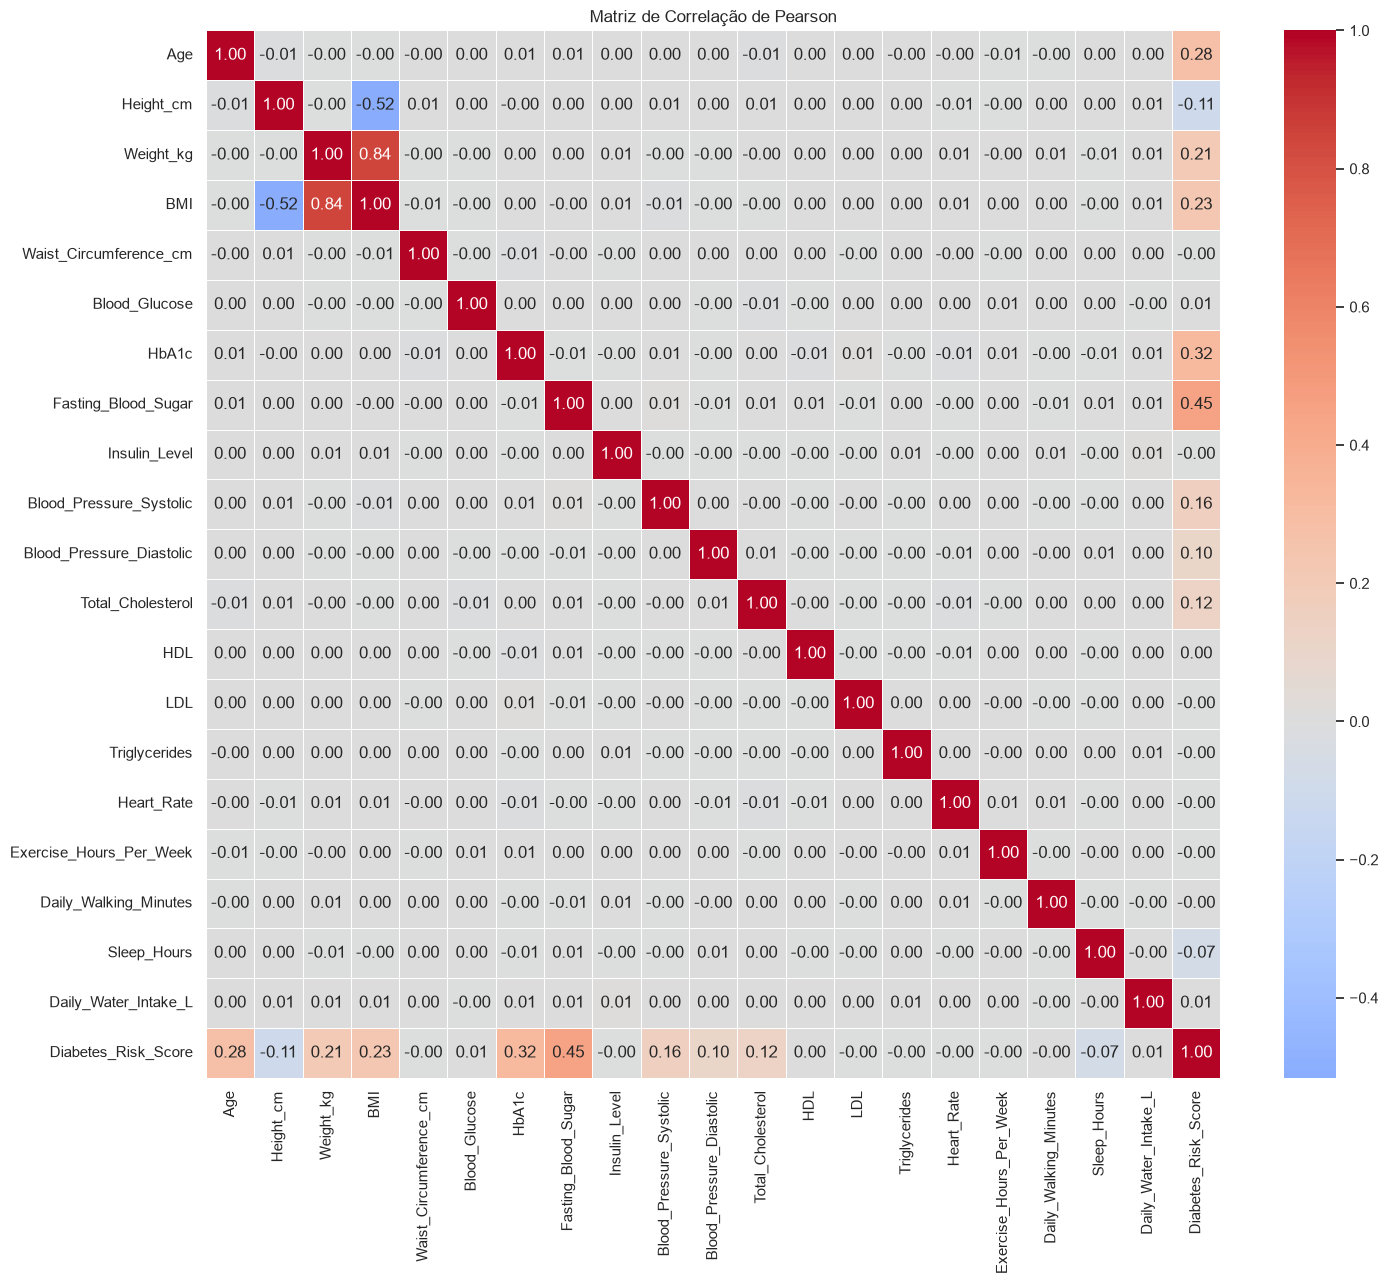

In [27]:
plot_correlation_matrix(matriz_corr)

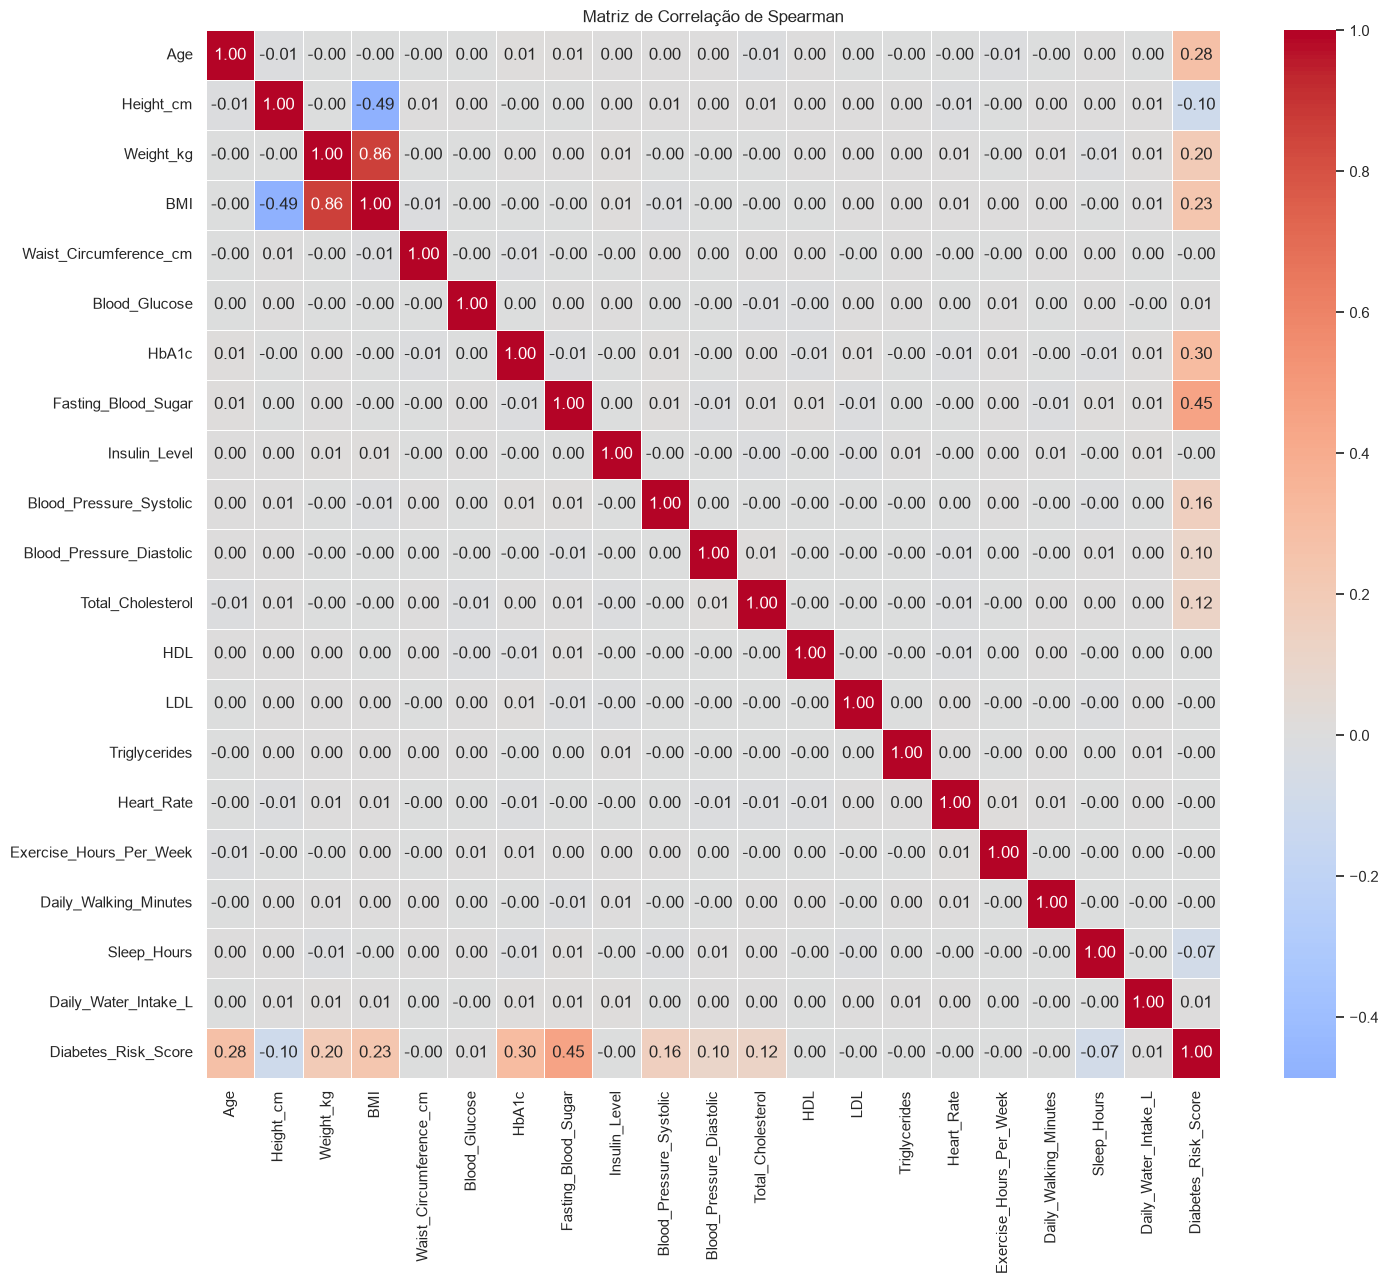

In [28]:
matriz_corr_spearman = df[variaveis].corr(method="spearman")

plt.figure(figsize=(15, 13))
sns.heatmap(matriz_corr_spearman, annot=True, cmap="coolwarm", fmt=".2f", center=0, linewidths=0.5)
plt.title("Matriz de Correlação de Spearman")
plt.tight_layout()
plt.show()